# Data Analyst portforlio – Ecommerce Retail Analysis
### Oscar Wang

**Jump to:** [0-2 Business Question](#0-2-business-question) • [4 Recommendations](#4-business-recommendations) • [5 Power BI Dashboard](#5-interactive-dashboard-power-bi)

---

# 0 Business Context and Business Question



## 0-1 Business Context

This dataset comes from a real UK-based online retailer specialising in unique all-occasion gifts, selling exclusively through online channels — no physical storefronts. Its customer base includes both individual shoppers and wholesale buyers, and the company has a full year of transaction history (Dec 2010 – Dec 2011) to draw on.

As the business has grown, customer outreach and product promotion have largely been applied evenly across the customer base. With a full year of data now available, leadership wants a clear, evidence-based view of where value actually comes from before deciding where to focus effort going forward.

## 0-2 Business Question

❓ **Which customers actually drive our revenue, and what specific actions — retention and product recommendations — will protect and grow it?**

## 0-3 Executive Summary

This analysis examines one year of transaction data (541,909 records, ~4,300
customers) from a UK-based online gift retailer. After cleaning the data (removing nulls, duplicates, and cancelled orders), two connected analyses were performed:

- **Customer Segmentation (RFM):** scored each customer on how recently, how often, and how much they purchase, grouping them into six actionable segments — Champions, Loyal Customers, New Customers, At Risk, Lost, and Need Attention.
- **Product Cross-Sell Analysis:** identified which products are most frequently bought together, broken down by segment, to surface concrete bundling opportunities.

💡💡**Headline finding:** Champions and Loyal Customers make up just **37.5%** of customers but generate **77.6%** of revenue — with Champions alone (19.3% of customers) driving 62% on their own.

## 0-4 Summary Business Recommendations

- 📍**Protect:** Champions (19.3% of customers, 62% of revenue) are the single
highest-priority segment — retain first, via loyalty rewards and featuring their signature bundle (Regency Cakestand + Roses Teacup).
- 💪**Grow:** Loyal Customers (18.2%, 15.6%) are the clearest growth opportunity — explicitly package and promote their top pairing (Feltcraft Cushion Owl + Red Floral Shoulder Bag) to nudge them toward Champion-level spend.
- ⏰**Quick win:** At Risk customers (8.8%, 7.2%) offer the highest ROI for a targeted win-back campaign using their known top purchase pattern.
- 🏃**Deprioritise:** Lost customers (30.5% of customers, only 7.6% of revenue) — low-cost automated reactivation only; not worth further investment.

---

# 1 Data Cleaning and Processing

In [1]:
import pandas as pd

# Note: this requires ecommerce_data.csv in the working directory — see Section 6 for the source link.
df = pd.read_csv("ecommerce_data.csv", encoding="latin-1")

In [2]:
# First, have an understanding of what dataset looks like
df.head(5)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


In [3]:
# Understand columns, data types. It contains around 540,000 transactions.
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200594 entries, 0 to 200593
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    200594 non-null  object 
 1   StockCode    200594 non-null  object 
 2   Description  199802 non-null  object 
 3   Quantity     200594 non-null  int64  
 4   InvoiceDate  200594 non-null  object 
 5   UnitPrice    200593 non-null  float64
 6   CustomerID   142574 non-null  float64
 7   Country      200593 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 12.2+ MB


**Note:** This dataset includes wholesale buyers (see 0-1 Business Context), which
explains occasional very large order quantities — treated as legitimate bulk
purchases, not outliers to remove.

## 1-1 Handle Null Values

In [4]:
missing_data = df.isna().sum()
missing_data_percentage = ((missing_data[missing_data>0] / df.shape[0])*100).round(2)
print(missing_data_percentage) # From output, we know only Description and CustomerID have null values

# Remove null values from dataset
df = df.dropna(subset = ['CustomerID', 'Description'])

Description     0.39
UnitPrice       0.00
CustomerID     28.92
Country         0.00
dtype: float64


## 1-2 Remove Duplicates

In [5]:
# Check Duplicated rows first
print('The total rows number is:', df.shape[0])
print('The duplicated rows number is:', df.duplicated().sum())

# Drop the duplicates
df = df.drop_duplicates()
print('The cleaned_dataset total rows number is:', df.shape[0])

The total rows number is: 142574
The duplicated rows number is: 1670
The cleaned_dataset total rows number is: 140904


## 1-3 Remove Cancellations

In [6]:
# Calculate the Revenue
df['Revenue'] = df['Quantity'] * df['UnitPrice']

# Flag the Cancellation orders
df['IsCancelled'] = df['InvoiceNo'].astype(str).str.startswith('C')

print('Total transactions:', df.shape[0])
print('Cancelled transactions:', df['IsCancelled'].sum())
print('Cancelled revenue impact:', df[df['IsCancelled']]['Revenue'].sum())

# Clean the dataset – remove cancellation orders
df_clean = df[~df['IsCancelled']].copy()
print('Remaining transactions for analysis:', df_clean.shape[0])

Total transactions: 140904
Cancelled transactions: 3388
Cancelled revenue impact: -206310.41
Remaining transactions for analysis: 137516


---

# 2 Data Analysis

## 2-1 Customer Segmentation Analysis

In [7]:
# First, transform InvoiceDate to proper format
df_clean['InvoiceDate'] = pd.to_datetime(df_clean['InvoiceDate'])

# Set a reference of a snapshot date – typically one day after the last transaction of the dataset
# This simulates "today" for the business, as if we're analysing the data right after it was collected
snapshot_date = df_clean['InvoiceDate'].max() + pd.Timedelta(days=1)
print('Snapshot date:', snapshot_date)


# Calculate the RFM for per customer
rfm = df_clean.groupby('CustomerID').agg(
    Recency = ('InvoiceDate', lambda x: (snapshot_date - x.max()).days),
    Frequency = ('InvoiceNo', 'nunique'),
    Monetary = ('Revenue', 'sum')
)
rfm.head(5)

Snapshot date: 2011-05-24 10:48:00


,Recency,Frequency,Monetary
CustomerID,,,
12346.0,126,1,77183.60
12347.0,47,3,1823.43
12348.0,49,3,1487.24
12350.0,110,1,334.40
12352.0,62,5,1561.81


| Metric | What it measures | How it's calculated |
|---|---|---|
| **Recency** | How recently a customer purchased | Days between snapshot date and their most recent purchase |
| **Frequency** | How often they purchase | Count of distinct invoices |
| **Monetary** | How much they spend | Sum of revenue across all transactions |


In [8]:
# Score each metric into quintiles (5 equal-sized groups)
# Recency: LOWER is better (recent = good), so scoring is reversed (5 = most recent)
rfm['R_Score'] = pd.qcut(rfm['Recency'], 5, labels=[5, 4, 3, 2, 1])

# Frequency and Monetary: HIGHER is better, so scoring is normal (5 = highest)
# For Frequency: manually defined, business-interpretable Frequency bins
rfm['F_Score'] = pd.cut(rfm['Frequency'], bins=[0, 1, 2, 4, 8, float('inf')], labels=[1, 2, 3, 4, 5])
rfm['M_Score'] = pd.qcut(rfm['Monetary'], 5, labels=[1, 2, 3, 4, 5])

rfm.head(5)

,Recency,Frequency,Monetary,R_Score,F_Score,M_Score
CustomerID,,,,,,
12346.0,126,1,77183.60,1,1,5
12347.0,47,3,1823.43,3,3,5
12348.0,49,3,1487.24,3,3,5
12350.0,110,1,334.40,1,1,2
12352.0,62,5,1561.81,3,4,5


**Note:** Frequency is heavily skewed (most customers buy 1–2 times), which broke quantile-based scoring (`pd.qcut`). Switched to manually defined, business-interpretable bins instead.

In [9]:
def segment_customer(row):
  r = int(row['R_Score'])
  f = int(row['F_Score'])

  if r >= 4 and f >= 4:
    return 'Champions'
  elif r >= 3 and f >= 3:
    return 'Loyal Customers'
  elif r >= 4 and f <= 2:
    return 'New Customers'
  elif r <= 2 and f >= 3:
    return 'At Risk'
  elif r <= 2 and f <= 2:
    return 'Lost'
  else:
    return 'Need Attention'

rfm['segment'] = rfm.apply(segment_customer, axis=1)
rfm.head(5)

,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,segment
CustomerID,,,,,,,
12346.0,126,1,77183.60,1,1,5,Lost
12347.0,47,3,1823.43,3,3,5,Loyal Customers
12348.0,49,3,1487.24,3,3,5,Loyal Customers
12350.0,110,1,334.40,1,1,2,Lost
12352.0,62,5,1561.81,3,4,5,Loyal Customers


### 2-2 Segment Profiling

In [10]:
# Profile each segment: size, behaviour, and revenue contribution

segment_profile = rfm.groupby('segment').agg(
    Customer_Count = ('segment', 'count'),
    Avg_Recency = ('Recency', 'mean'),
    Avg_Frequency = ('Frequency', 'mean'),
    Avg_Monetary = ('Monetary', 'mean'),
    Total_Revenue = ('Monetary', 'sum')
).round(1)

# Add the percentage column
segment_profile['% of Customer'] = (segment_profile['Customer_Count'] / segment_profile['Customer_Count'].sum() * 100).round(1)
segment_profile['% of Revenue'] = (segment_profile['Total_Revenue'] / segment_profile['Total_Revenue'].sum() * 100).round(1)

# Reorder by revenue
segment_profile = segment_profile.sort_values('Total_Revenue', ascending=False)
segment_profile

,Customer_Count,Avg_Recency,Avg_Frequency,Avg_Monetary,Total_Revenue,% of Customer,% of Revenue
segment,,,,,,,
Champions,302,11.6,9.5,5040.0,1522073.4,11.3,48.1
Loyal Customers,388,26.4,3.6,1480.3,574350.4,14.6,18.1
Lost,956,115.3,1.2,475.4,454444.3,35.9,14.4
New Customers,537,15.9,1.5,576.1,309347.3,20.2,9.8
Need Attention,393,49.0,1.4,491.8,193271.1,14.8,6.1
At Risk,87,96.1,4.0,1299.0,113009.1,3.3,3.6


### 2-3 Visualisation

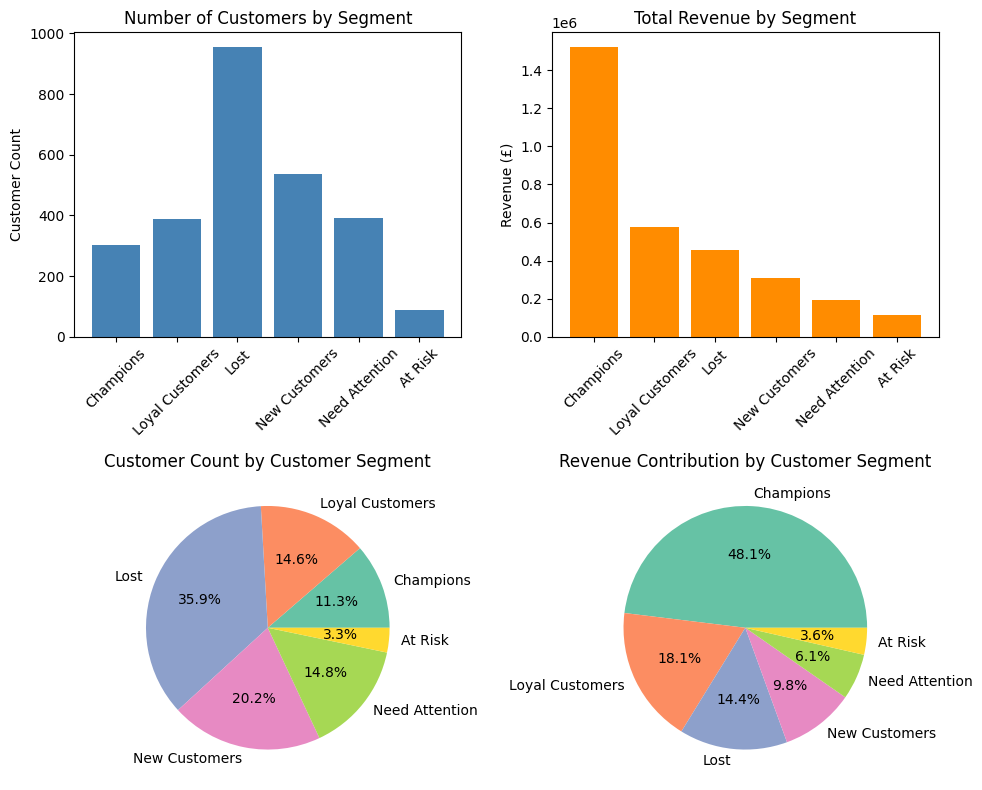

In [11]:
import matplotlib.pyplot as plt

# Set up side-by-side charts
fig, axes = plt.subplots(2, 2, figsize=(10, 8))

# Chart 1: Customer count by segment
axes[0, 0].bar(segment_profile.index, segment_profile['Customer_Count'], color='steelblue')
axes[0, 0].set_title('Number of Customers by Segment')
axes[0, 0].set_ylabel('Customer Count')
axes[0, 0].tick_params(axis='x', rotation=45)

# Chart 2: Revenue contribution by segment
axes[0, 1].bar(segment_profile.index, segment_profile['Total_Revenue'], color='darkorange')
axes[0, 1].set_title('Total Revenue by Segment')
axes[0, 1].set_ylabel('Revenue (£)')
axes[0, 1].tick_params(axis='x', rotation=45)

# Pie Chart 3: Revenue by segment
axes[1, 0].pie(segment_profile['Customer_Count'],
        labels=segment_profile.index,
        autopct='%1.1f%%',
        colors=plt.cm.Set2.colors)
axes[1, 0].set_title('Customer Count by Customer Segment')

# Pie Chart 4: Revenue by segment
axes[1, 1].pie(segment_profile['Total_Revenue'],
        labels=segment_profile.index,
        autopct='%1.1f%%',
        colors=plt.cm.Set2.colors)
axes[1, 1].set_title('Revenue Contribution by Customer Segment')


plt.tight_layout()
plt.show()

---

## 3-1 Product Cross-Sell Analysis

The table belows demonstrates **Champions** and **Loyal Customers** create most of the values. This section explores the exact **basket driving bundles**.

In [12]:
segment_profile.loc['Total'] = segment_profile.sum(axis=0)
segment_profile[['Customer_Count', '% of Customer', '% of Revenue', 'Total_Revenue', 'Avg_Monetary']].rename(columns={
    'Customer_Count': 'Customer Count',
    'Total_Revenue': 'Total Revenue',
    'Avg_Monetary': 'Avg Spend'})

,Customer Count,% of Customer,% of Revenue,Total Revenue,Avg Spend
segment,,,,,
Champions,302.0,11.3,48.1,1522073.4,5040.0
Loyal Customers,388.0,14.6,18.1,574350.4,1480.3
Lost,956.0,35.9,14.4,454444.3,475.4
New Customers,537.0,20.2,9.8,309347.3,576.1
Need Attention,393.0,14.8,6.1,193271.1,491.8
At Risk,87.0,3.3,3.6,113009.1,1299.0
Total,2663.0,100.1,100.1,3166495.6,9362.6


### 3-2 Looking for Bundles based on Transactions

In [13]:
# Mark the Revenue and cx segmentation on Invoice
df_clean = df_clean.merge(rfm[['segment']], left_on='CustomerID', right_index=True, how='left') # Run once — re-running will duplicate the segment column

# Transform the transaction-level data to invoice-level data
basket = df_clean.groupby('InvoiceNo').agg(
    Item = ('Description', lambda x: list(x)),
    Revenue = ('Revenue','sum'),
    Segment = ('segment', 'first')).reset_index()
basket.columns = ['Invoice', 'Item', 'Basket_Revenue', 'Segment']

# Keep only multi-item transactions, where single-item transaction has no pairs to find
basket['Item_Count'] = basket['Item'].apply(len)
basket_multi = basket[basket['Item_Count'] > 1].copy()

print(f'Total Invoice:  {basket.shape[0]}')
print(f'Invoice with 2+ Items: {basket_multi.shape[0]}, {round(basket_multi.shape[0] / basket.shape[0]  * 100, 2)}% of the total transactions')

basket_multi.head(5)

Total Invoice:  7048
Invoice with 2+ Items: 6493, 92.13% of the total transactions


,Invoice,Item,Basket_Revenue,Segment,Item_Count
0,536365,"[WHITE HANGING HEART T-LIGHT HOLDER, WHITE MET...",139.12,At Risk,7
1,536366,"[HAND WARMER UNION JACK, HAND WARMER RED POLKA...",22.20,At Risk,2
2,536367,"[ASSORTED COLOUR BIRD ORNAMENT, POPPY'S PLAYHO...",278.73,Champions,12
3,536368,"[JAM MAKING SET WITH JARS, RED COAT RACK PARIS...",70.05,Champions,4
5,536370,"[ALARM CLOCK BAKELIKE PINK, ALARM CLOCK BAKELI...",855.86,Champions,20


In [14]:
basket_summary = basket_multi.groupby('Segment').agg(
    Basket_Num = ('Invoice', 'count'),
    Segment_Revenue = ('Basket_Revenue', 'sum'))

basket_summary

,Basket_Num,Segment_Revenue
Segment,,
At Risk,302,107106.840
Champions,2574,1458117.710
Lost,1031,356720.070
Loyal Customers,1320,559600.680
Need Attention,506,188322.360
New Customers,760,301668.281


### 3-3 Occuring Product Pairs in Different Segments

In [15]:
# Assess each basket product pairs
from itertools import combinations
from collections import Counter

def pair_comparison(df):
    pair_counts = Counter()   # fresh Counters PER GROUP
    pair_revenue = Counter()

    for _, row in df.iterrows():
        unique_items = set(row['Item'])
        for pair in combinations(sorted(unique_items), 2):
            pair_counts[pair] += 1
            pair_revenue[pair] += row['Basket_Revenue']

    # Build and RETURN a DataFrame for this one segment's group
    result = pd.DataFrame(pair_counts.items(), columns=['Pair', 'Count'])
    result['Revenue'] = result['Pair'].map(pair_revenue).round(2)
    return result.sort_values('Revenue', ascending=False)

# apply the function to each segment's group, combine results, keep segment as a label
pairs_by_segment = basket_multi.groupby('Segment').apply(pair_comparison, include_groups=False)
pairs_by_segment.head(5)

Pair  Count  \
Segment                                                                  
At Risk 6047  (FELTCRAFT CUSHION BUTTERFLY, FELTCRAFT CUSHIO...     10   
        6054  (FELTCRAFT CUSHION OWL, FELTCRAFT CUSHION RABBIT)     10   
        6048  (FELTCRAFT CUSHION BUTTERFLY, FELTCRAFT CUSHIO...     10   
        120   (WOODEN FRAME ANTIQUE WHITE , WOODEN PICTURE F...     26   
        11    (KNITTED UNION FLAG HOT WATER BOTTLE, RED WOOL...     21   

               Revenue  
Segment                 
At Risk 6047  12006.75  
        6054  10461.51  
        6048  10264.29  
        120   10068.72  
        11     9256.06

Look at the Pair Table, lots of them **share the same product type but colors**, which means a product set rather than a cross-sell bundle. (e.g. Black Towel vs Green Towel) **Filtering the trivial pairs** would benefit insights.

In [16]:
# flag pairs where both items share a common word (likely same product line)
def share_keywords(pair):
  words_a = set(pair[0].split())
  words_b = set(pair[1].split())
  return len(words_a & words_b) >= 2 # 2+ shared words = likely same line
pairs_by_segment['Likely_Same_Line'] = pairs_by_segment['Pair'].apply(share_keywords)
result = pairs_by_segment[~pairs_by_segment['Likely_Same_Line']].sort_values('Revenue', ascending=False).groupby('Segment').head(3)  # genuinely different products bought together


# Tidy up the result table
result = result.merge(basket_summary, left_index=True, right_index=True, how='left').reset_index()
result['% Revenue'] = (result['Revenue']/result['Segment_Revenue']*100).round(2)
result['% Basket'] = (result['Count']/result['Basket_Num']*100).round(2)
# Note: % Revenue and % Basket here are each pair's share within its own segment's basket revenue/count, not of the company total numbers.

result[['Segment', 'Pair', 'Revenue', '% Revenue', '% Basket']]

,Segment,Pair,Revenue,% Revenue,% Basket
0,Champions,"(REGENCY CAKESTAND 3 TIER, SPACEBOY LUNCH BOX )",128170.79,8.79,1.59
1,Champions,"(PACK OF 72 RETROSPOT CAKE CASES, SPACEBOY LUN...",121970.54,8.36,1.20
2,Champions,"(REGENCY CAKESTAND 3 TIER, ROSES REGENCY TEACU...",107600.84,7.38,3.03
3,Loyal Customers,"(GIN + TONIC DIET METAL SIGN, WHITE HANGING HE...",45482.75,8.13,1.44
4,Loyal Customers,"(FAIRY CAKE FLANNEL ASSORTED COLOUR, WHITE HAN...",37156.30,6.64,0.23
5,Loyal Customers,"(FAIRY CAKE FLANNEL ASSORTED COLOUR, GIN + TON...",36696.80,6.56,0.15
6,Lost,"(JAM MAKING SET WITH JARS, SET OF 3 CAKE TINS ...",27553.05,7.72,3.59
7,Lost,"(HEART OF WICKER LARGE, WHITE HANGING HEART T-...",22470.12,6.30,3.30
8,New Customers,"(LUNCH BAG RED RETROSPOT, STRAWBERRY PICNIC ...",22357.96,7.41,1.97
9,Lost,"(HEART OF WICKER SMALL, WHITE HANGING HEART T-...",21379.06,5.99,3.10


---

# 4 Business Recommendations

Based on RFM segmentation of 4339 customers (£8,887,209 total revenue) and cross-sell analysis of 17,143 multi-item baskets:

### **Headline finding:** Champions + Loyal Customers make up just **37.5%** of customers but generate **77.6%** of revenue — reinforcing retention-focused spend over broad acquisition.

Note: "Bundle revenue" reflects total basket value for orders containing that pair, not the pair's isolated revenue — used here as a ranking signal, not a direct revenue claim.

---

### 🏆 Champions — 19.3% of customers, 62.0% of revenue
This segment alone justifies the majority of retention investment. Their strongest purchase pattern is **Regency Cakestand 3-Tier + Roses Regency Teacup**, bought together 225 times — the single most reliable combination in the dataset.

**Action:** feature this bundle in VIP/early-access campaigns, and treat it as the benchmark "premium behavior" other segments should be nudged toward. At an average £6,585 spend per customer, retaining even a handful of Champions materially protects revenue — prioritise loyalty rewards and referral incentives here first.

**Illustrative impact:** losing just 5% of Champions (~42 customers) at their average spend (£6,585) would cost roughly **£277,000** in annual revenue — underscoring why retention here is a priority, not a nice-to-have.

### 💚 Loyal Customers — 18.2% of customers, 15.6% of revenue
The clearest growth lever: large enough to matter, not yet spending like Champions. Their own top pairing — **Feltcraft Cushion Owl + Red Floral Shoulder Bag** — is currently likely bought as two separate line items.

**Action:** package this explicitly as a bundle and promote it directly to this segment; a concrete, testable step toward closing the gap with Champions.

**Illustrative impact:** a 10% uplift in Loyal Customers' average spend (£1,752 → ~£1,927) would add roughly **£138,000** in incremental annual revenue — a concrete, trackable target for the bundle promotion above.

---

### Other segments (brief)
- **Lost (30.5% of customers, 7.6% of revenue):** Largest group by headcount but lowest value — low-cost automated reactivation only; not worth further analysis investment.

- **At Risk (8.8%, 7.2%):** Small but high-ROI to re-engage — target with a "we miss you" email featuring their historical top pair (Gin+Tonic Sign + Heart T-Light Holder).

- **New Customers (12.2%, 4.9%):** Early signal shows interest in the Regency product line — worth surfacing in post-purchase recommendations to drive a second order.

- **Need Attention (11.0%, 2.7%):** Monitor with light-touch newsletters; no dedicated campaign spend justified yet.

# 5 Power BI

In [17]:
# Export tables for Power BI

# 1. Segment profile
segment_profile.drop('Total', errors='ignore').reset_index().to_csv('segment_profile.csv', index=False)

# 2. Top bundles by segment — split the Pair tuple into two clean columns
#    (a raw tuple like ('Item A', 'Item B') would export as an ugly string otherwise)
result['Item_A'] = result['Pair'].apply(lambda p: p[0])
result['Item_B'] = result['Pair'].apply(lambda p: p[1])
result[['Segment', 'Item_A', 'Item_B', 'Revenue', '% Revenue', '% Basket']].to_csv('top_bundles_by_segment.csv', index=False)

# 3. Monthly Trend plot chart
df_clean['InvoiceMonth'] = df_clean['InvoiceDate'].dt.to_period('M').astype(str)

monthly_segment_revenue = df_clean.groupby(['InvoiceMonth', 'segment'])['Revenue'].sum().reset_index()
monthly_segment_revenue.to_csv('monthly_revenue_by_segment.csv', index=False)

# Download all three
from google.colab import files
#files.download('segment_profile.csv')
#files.download('top_bundles_by_segment.csv')
#files.download('monthly_revenue_by_segment.csv')

## Interactive Dashboard (Power BI)

To extend this analysis into an interactive format, I built a Power BI dashboard covering segment performance, monthly revenue trends, and cross-sell bundles — including a drill-through page for deeper per-segment detail.

**Interactive features:**
- A segment slicer that filters the customer count, revenue, and bundle visuals
simultaneously
- A drill-through page: right-clicking any segment opens a dedicated detail view with that segment's revenue, trend, and top bundles

**Note on access:** Power BI's "Publish to Web" requires a Microsoft work/school account rather than a personal email — a platform restriction. The `.pbix` file is included in this repository, so anyone with Power BI Desktop (free) can open it and interact with it directly.

### **Main Dashboard**
![Main Dashboard](https://github.com/oscarwanghj/UK-ecommerce-data-analysis-portfolio/blob/main/main_dashboard.png?raw=true&v1)

### **Segment Drill-Through Example (Champions)**
![Champions Drill-Through](https://github.com/oscarwanghj/UK-ecommerce-data-analysis-portfolio/blob/main/champions_drillthrough.png?raw=true&v1)

# 6 Reference

**Source**

This dataset can be downloaded from https://www.kaggle.com/datasets/carrie1/ecommerce-data/data

The UCI Machine Learning Repository has made this dataset containing actual transactions from 2010 and 2011. The dataset is maintained on their site, where it can be found by the title "Online Retail".

**Acknowledgements**

Per the UCI Machine Learning Repository, this data was made available by Dr Daqing Chen, Director: Public Analytics group. chend '@' lsbu.ac.uk, School of Engineering, London South Bank University, London SE1 0AA, UK.

